# Oslo EV charging demand: walkthrough

This notebook tells the story of the project step by step, using the outputs of the scripts in `src/`.
Run `python src/build_dataset.py`, `python src/train.py`, `python src/replicate_team.py` and `python src/analysis.py` first.

**Question:** how full will each public charging station in Oslo be in 1, 3 and 6 hours?

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.precision", 3)
ev = pd.read_csv(ROOT / "data/raw/nobil_events_oslo_2026-03.csv.gz", parse_dates=["received_at"])
sh = pd.read_csv(ROOT / "data/processed/station_hour.csv.gz", parse_dates=["hour"])
print(f"{len(ev):,} status messages | {ev.station_id.nunique():,} stations | {ev.charger_id.nunique():,} chargers")
ev.head()

107,127 status messages | 1,266 stations | 3,144 chargers


,received_at,station_id,charger_id,status,payload_sha1
0,2026-03-22 13:16:36.892497+00:00,NOR_71149,16bb0925-37db-4a2d-90af-15490f99491e,BLOCKED,29cadd31c28842307f280b83086578d71deb786c
1,2026-03-22 13:16:38.517565+00:00,NOR_52334,309c7ea3fcfc4b3ab3e8c41a,OUTOFORDER,2716332649e374d6cc0accfdb9e6fedd9d6dfd0e
2,2026-03-22 13:16:39.220705+00:00,NOR_52334,e455b38385914c7aabd305fc,OUTOFORDER,865f58e307e544241eae04669f20284a93834a2b
3,2026-03-22 13:16:45.361504+00:00,NOR_70994,31aab65d-a0bd-4b67-a8b9-23f1ce486ea6,CHARGING,5ff3be57f0b2b3aa0bb6ae15f73817b449819908
4,2026-03-22 13:16:53.069659+00:00,NOR_71149,14dec7c7-9a00-4b41-abb3-d7fdbb13907b,BLOCKED,40066faebea8b81acedc53c81ca985d176f1d53f


## 1. The raw data is a stream of *changes*

NOBIL sends a message only when a charger changes state. A charger that starts charging at 20:10 and finishes at 21:35 produces two messages, and silence in between.

In [2]:
ev.status.value_counts(normalize=True).rename("share of messages").to_frame()

,share of messages
status,
AVAILABLE,0.370
CHARGING,0.293
OUTOFORDER,0.205
BLOCKED,0.122
UNKNOWN,0.011


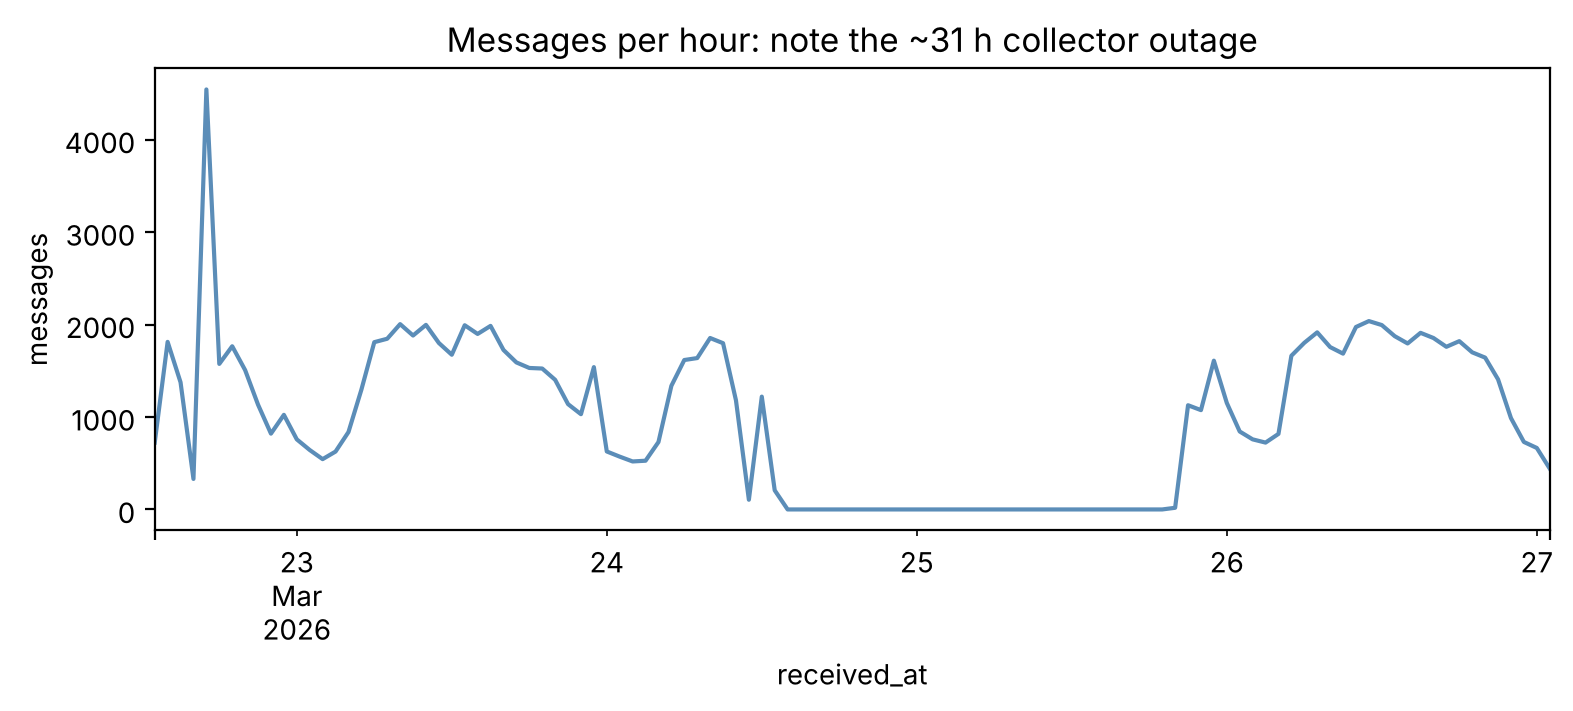

In [3]:
per_hour = ev.set_index("received_at").resample("h").size()
ax = per_hour.plot(figsize=(9, 3), color="#5b8db8", title="Messages per hour: note the ~31 h collector outage")
ax.set_ylabel("messages"); plt.show()

## 2. From messages to real occupancy

For every charger I keep its last known state on a 5-minute grid (never across the outage), then compute
`occupancy = charging chargers / working chargers`, averaged over each hour. Example: one station over one day.

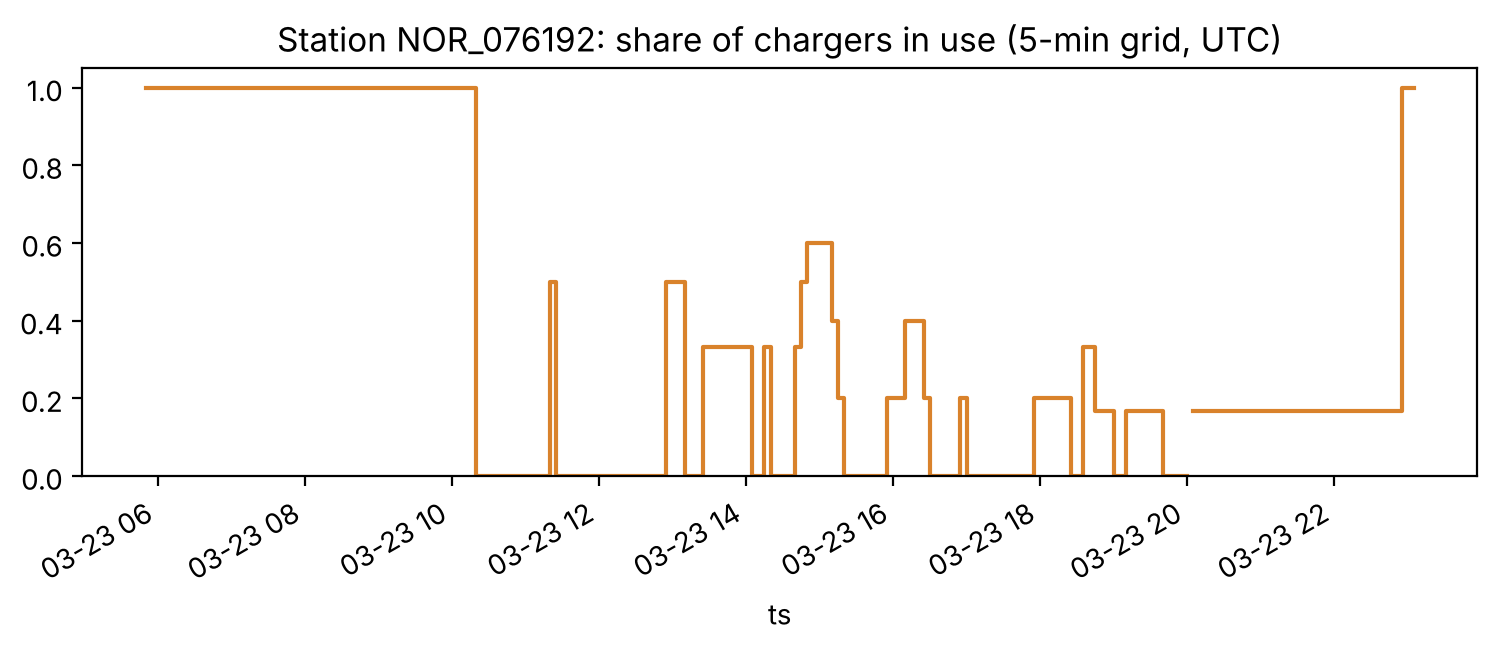

In [4]:
from oslo_ev.occupancy import split_segments, replay_states
sid = sh.groupby("station_id").operational_chargers.mean().loc[lambda s: s.between(3, 6)].index[0]
one = split_segments(ev[ev.station_id == sid])
st = replay_states(one, "5min")
day = st[st.ts.dt.date == pd.Timestamp("2026-03-23").date()]
occ5 = day.groupby("ts").status.apply(lambda s: (s == "CHARGING").sum() / s.isin(["AVAILABLE", "CHARGING", "BLOCKED"]).sum())
ax = occ5.plot(drawstyle="steps-post", figsize=(9, 3), color="#d9822b", title=f"Station {sid}: share of chargers in use (5-min grid, UTC)")
ax.set_ylim(0, 1.05); plt.show()

## 3. Why not the original target?

The team project used *the share of messages that say CHARGING* in each hour. Two problems:
1. About 3 in 4 station-hours have no message at all, so they could not be modelled.
2. Where both exist, it correlates only r ≈ 0.19 with real occupancy.

In [5]:
print(json.load(open(ROOT / "reports/team_replication_extra.json")))

{'peak_precision_0.8': 0.8889, 'peak_recall_0.8': 0.092, 'corr_event_ratio_vs_true_occupancy': 0.1881, 'share_station_hours_with_no_message': 0.716}


![](../reports/figures/event_ratio_vs_true_occupancy.png)

## 4. Daily pattern

![](../reports/figures/daily_profile_occupancy_vs_traffic.png)

Oslo charges at night (home and residential street charging), the opposite of road traffic.

## 5. Results (chronological split, last 17 hours as test)

In [6]:
m = pd.read_csv(ROOT / "reports/metrics.csv")
m.pivot(index="model", columns="horizon", values="MAE").sort_values("t+6")

horizon,t+1,t+3,t+6
model,,,
Gradient Boosting,0.101,0.207,0.254
Random Forest,0.102,0.212,0.262
Linear regression,0.119,0.236,0.293
Baseline: same as now,0.101,0.218,0.320
Baseline: average,0.326,0.325,0.327


![](../reports/figures/mae_by_model_and_horizon.png)

## 6. The original team model, reproduced

A faithful Python port of the team's R code (`src/replicate_team.py`) gives results very close to the final report
(t+1: MAE 0.20 vs 0.19 reported, R² 0.29 vs 0.28). It also shows that longer horizons were evaluated on fewer,
busier stations (592 → 107), which is why its error *seemed* to fall with the horizon.

In [7]:
pd.read_csv(ROOT / "reports/team_vs_this_version.csv")

,horizon,team_rows,team_stations,team_R2,team_MAE_vs_avg_baseline_pct,this_rows,this_R2,this_MAE_vs_avg_baseline_pct
0,t+1,5489,592,0.293,20.719,68502,0.793,69.129
1,t+3,3476,204,0.153,14.174,61971,0.437,36.179
2,t+6,2375,107,0.136,12.611,52697,0.256,22.345


## 7. Where the model struggles

![](../reports/figures/error_by_station_size.png)

Small stations (1–2 chargers) flip between 0 % and 100 % with a single car, so they are the hardest to predict.

## 8. Saturation alerts

![](../reports/figures/peak_alert_tradeoff.png)

In [8]:
pd.read_csv(ROOT / "reports/peak_alerts.csv")

,threshold,precision,recall,f1
0,0.50,0.594,0.920,0.722
1,0.55,0.733,0.893,0.805
2,0.60,0.771,0.879,0.822
3,0.65,0.790,0.862,0.825
4,0.70,0.814,0.836,0.825
5,0.75,0.833,0.798,0.815
6,0.80,0.852,0.751,0.798
7,0.85,0.875,0.659,0.752
8,0.90,0.911,0.533,0.672


## 9. Limitations

* About 3 days of real-time data, one test weekday: no weekly or seasonal learning yet.
* Occupancy is not energy: a parked car that has finished charging still counts.
* Traffic is city-wide; linking each station to its nearest sensor is the next step.